<a href="https://colab.research.google.com/github/nisaerdemli/imageprocessing/blob/main/%C3%B6dev4_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

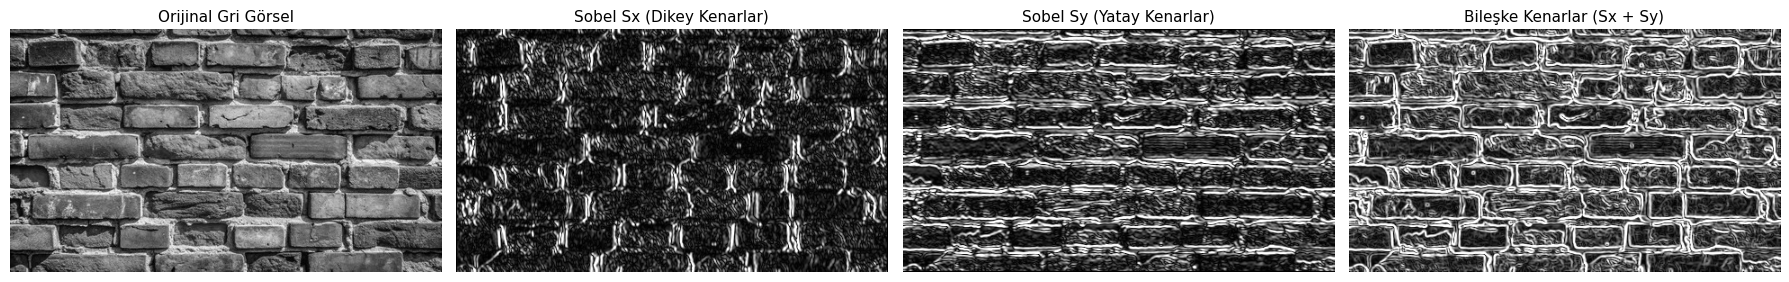

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Görseli gri tonlamalı olarak oku
# (Dosya adını Colab'deki adıyla eşleştirin, örn: 'duvar.jpeg')
image_path = 'duvar.jpeg'
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if image is None:
    raise FileNotFoundError(f"'{image_path}' dosyası bulunamadı. Lütfen yüklediğiniz dosya adını kontrol edin.")

# 2. Tuğla dokusundaki yüksek frekanslı gürültüleri azaltmak için Gauss yumuşatma
blurred_image = cv2.GaussianBlur(image, (3, 3), sigmaX=1.0)

# 3. 3x3 Sobel Filtre Çekirdeklerinin Tanımlanması
sobel_x_kernel = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=np.float32)

sobel_y_kernel = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
], dtype=np.float32)

# 4. Konvolüsyon işlemleri (Negatif gradyanları korumak için CV_64F kullanılır)
sobel_x = cv2.filter2D(blurred_image, cv2.CV_64F, sobel_x_kernel)
sobel_y = cv2.filter2D(blurred_image, cv2.CV_64F, sobel_y_kernel)

# 5. Mutlak değerleri alıp 8-bit (0-255) aralığına normalize etme
abs_sobel_x = np.uint8(np.clip(np.absolute(sobel_x), 0, 255))
abs_sobel_y = np.uint8(np.clip(np.absolute(sobel_y), 0, 255))

# 6. Bileşke Kenar Büyüklüğü (Gradient Magnitude): sqrt(Sx^2 + Sy^2)
magnitude = np.sqrt(sobel_x**2 + sobel_y**2)
magnitude = np.uint8(np.clip(magnitude, 0, 255))

# 7. Sonuçları yan yana görselleştirme
plt.figure(figsize=(18, 5))

plt.subplot(1, 4, 1)
plt.title("Orijinal Gri Görsel", fontsize=11)
plt.imshow(image, cmap='gray')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.title("Sobel Sx (Dikey Kenarlar)", fontsize=11)
plt.imshow(abs_sobel_x, cmap='gray')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.title("Sobel Sy (Yatay Kenarlar)", fontsize=11)
plt.imshow(abs_sobel_y, cmap='gray')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.title("Bileşke Kenarlar (Sx + Sy)", fontsize=11)
plt.imshow(magnitude, cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()